# Aula 21 — Árvores binárias

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

O historiador SCADA armazena os eventos de uma missão e oferece consultas para a HMI: localizar uma ocorrência, recuperar uma janela de tempo e reconstruir a ordem cronológica. A estrutura estudada é uma árvore binária de busca (BST).

A chave é `(instante_ms, id)`, para manter dois eventos simultâneos distintos. O ID é da ocorrência, não o código do tipo. O histórico desta aula usa os mesmos registros da Aula 20. Cada árvore aceita apenas uma missão; unir missões exigiria ampliar a chave ou normalizar o tempo.

## 2. Modelo e fundamentação

Uma árvore binária possui até dois filhos por nó. Uma BST exige que toda a subárvore esquerda tenha chaves menores e toda a direita tenha chaves maiores. A ordem das tuplas é lexicográfica: primeiro o instante, depois o ID.

Inserção e busca custam $O(h+1)$, onde $h$ é a altura em arestas. O percurso em ordem produz chaves ordenadas; pré-ordem visita raiz–esquerda–direita e pós-ordem visita esquerda–direita–raiz. Os percursos completos custam $O(n)$. A consulta inclusiva de intervalo poda ramos e custa $O(h+k+1)$ para $k$ resultados.

A altura da árvore vazia é −1. Uma sequência crescente pode criar altura $n-1$. Inserir medianas de um conjunto já conhecido produz uma referência equilibrada, mas não implementa AVL. As operações são iterativas para evitar o limite de recursão em árvores degeneradas.

## 3. Procedimento e demonstração

1. Inserir os registros em ordem embaralhada com semente fixa.
2. Buscar uma chave presente e outra ausente.
3. Exibir os três percursos e comparar o percurso em ordem com `sorted`.
4. Consultar o instante de um alerta e sua pausa simultânea.
5. Construir árvores com chegada cronológica e mediana-primeiro; comparar alturas.

Pergunta para a apresentação: por que receber eventos em ordem cronológica pode ser ruim para uma BST simples? Porque cada inserção pode seguir até a extremidade direita, aumentando progressivamente a altura.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
class Historico:
    def __init__(self):
        self.raiz = None; self.ids = set(); self.missao = None

    def inserir(self, evento):
        if type(evento['id']) is not int or type(evento['instante_ms']) is not int:
            raise ValueError('Instante e ID devem ser inteiros')
        if evento['id'] in self.ids or evento['instante_ms'] < 0:
            raise ValueError('Duplicata ou instante negativo')
        if self.missao is not None and evento['missao'] != self.missao:
            raise ValueError('Use um histórico por missão')
        novo = NoBST((evento['instante_ms'], evento['id']), dict(evento)); n = 0
        if self.raiz is None: self.raiz = novo
        else:
            no = self.raiz
            while True:
                n += 1; lado = 'esq' if novo.chave < no.chave else 'dir'
                if getattr(no, lado) is None: setattr(no, lado, novo); break
                no = getattr(no, lado)
        self.ids.add(evento['id']); self.missao = evento['missao']
        return n

    def buscar(self, chave):
        no = self.raiz; visitas = 0
        while no:
            visitas += 1
            if chave == no.chave: return dict(no.evento), visitas
            no = no.esq if chave < no.chave else no.dir
        return None, visitas

    def percurso(self, ordem='em'):
        if ordem not in ('em', 'pre', 'pos'): raise ValueError('Ordem inválida')
        pilha = [(self.raiz, False)]; saida = []
        while pilha:
            no, emitir = pilha.pop()
            if no is None: continue
            if emitir: saida.append(dict(no.evento)); continue
            itens = {'em': [(no.dir, False), (no, True), (no.esq, False)],
                     'pre': [(no.dir, False), (no.esq, False), (no, True)],
                     'pos': [(no, True), (no.dir, False), (no.esq, False)]}
            pilha.extend(itens[ordem])
        return saida

    def intervalo(self, inicio, fim):
        if inicio > fim: raise ValueError('Intervalo invertido')
        no = self.raiz; pilha = []; saida = []
        while no or pilha:
            while no:
                if no.chave[0] < inicio: no = no.dir
                else: pilha.append(no); no = no.esq
            if not pilha: break
            no = pilha.pop()
            if no.chave[0] > fim: break
            saida.append(dict(no.evento)); no = no.dir
        return saida

    def altura(self):
        h = -1; pilha = [(self.raiz, 0)]
        while pilha:
            no, d = pilha.pop()
            if no: h = max(h, d); pilha.extend([(no.esq, d+1), (no.dir, d+1)])
        return h


### Inserções, buscas e percursos

In [3]:
ev=gerar_eventos();chegada=list(ev);random.Random(21).shuffle(chegada)
hist=Historico()
for e in chegada:hist.inserir(e)
for ordem in ['em','pre','pos']:print(ordem,[e['id'] for e in hist.percurso(ordem)[:15]])
print('Busca existente:',hist.buscar((ev[0]['instante_ms'],ev[0]['id'])))
print('Busca ausente:',hist.buscar((999999,999999)))
instante=next(e['instante_ms'] for e in ev if e['tipo']==4)
print('Simultâneos:',hist.intervalo(instante,instante))
assert hist.percurso()==sorted(ev,key=lambda e:(e['instante_ms'],e['id']))

em [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
pre [162, 44, 36, 33, 13, 3, 2, 1, 7, 5, 4, 6, 8, 12, 10]
pos [1, 2, 4, 6, 5, 9, 11, 10, 12, 8, 7, 3, 15, 14, 16]
Busca existente: ({'instante_ms': 0, 'id': 1, 'tipo': 0, 'missao': 'SIM_003', 'talhao': 'T1'}, 8)
Busca ausente: (None, 5)
Simultâneos: [{'instante_ms': 74000, 'id': 30, 'tipo': 4, 'missao': 'SIM_003', 'talhao': 'T5'}, {'instante_ms': 74000, 'id': 31, 'tipo': 2, 'missao': 'SIM_003', 'talhao': 'T5'}]


### Degeneração por chegada ordenada

Embaralhada | altura: 13 | nós examinados nas inserções: 1461
Cronológica | altura: 193 | nós examinados nas inserções: 18721
Mediana-primeiro | altura: 7 | nós examinados nas inserções: 1111


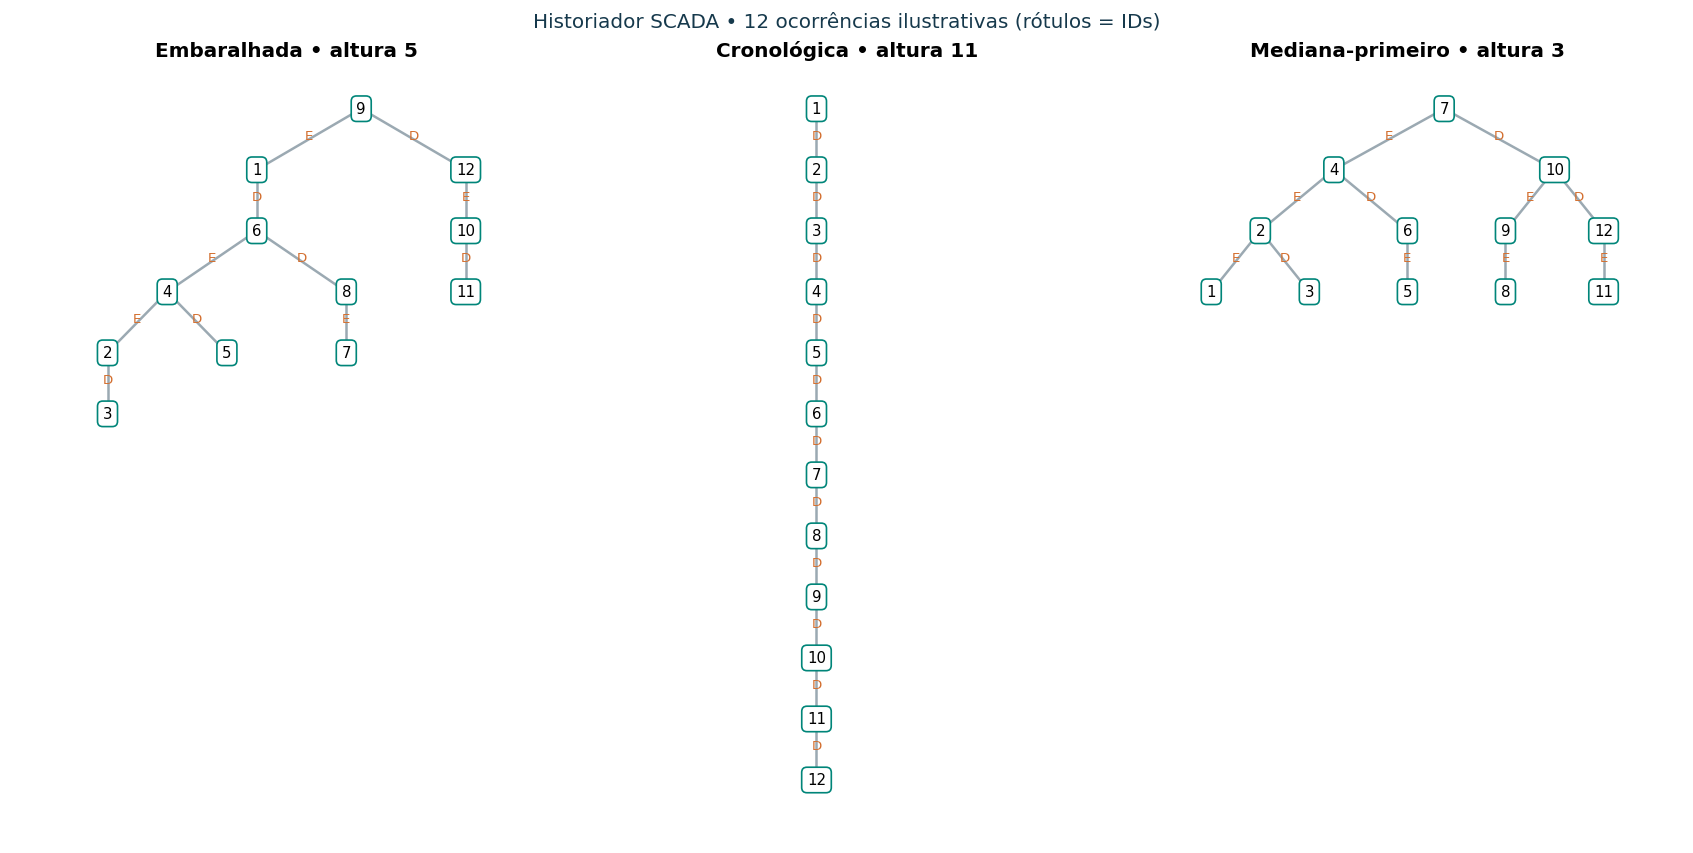

In [4]:
for nome,ordem in [('Embaralhada',chegada),('Cronológica',ev),('Mediana-primeiro',ordem_mediana(ev))]:
    h=Historico()
    visitas=sum(h.inserir(e) for e in ordem)
    print(nome,'| altura:',h.altura(),'| nós examinados nas inserções:',visitas)
vis.figura21();plt.show()

### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [5]:
RESUMO = TESTES[21]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 21: APROVADAS')

{
  "eventos": 194,
  "altura_embaralhada": 13,
  "altura_ordenada": 193
}
Verificações da aula 21: APROVADAS


## 5. Interpretação, limites e continuidade

A BST organiza dados, sem escolher comandos ou diagnosticar falhas. Não é a árvore de comportamento da Aula 25 nem a árvore aprendida da Aula 27. A versão didática não oferece persistência, acesso concorrente ou exclusão. A regra de ID único evita reinserções, mas sua atribuição deve ser consistente na aquisição.

Na Aula 28, cada decisão do supervisor vira um registro consultável. Em uma implantação real, o historiador exigiria persistência e sincronização de relógios; a BST aqui demonstra a estrutura de indexação.

## 6. Referências

- [Princeton — Binary Search Trees](https://algs4.cs.princeton.edu/32bst/).
- [Referência curricular do professor](https://github.com/valerio-unifei/ECAA08-2026.2-Projeto/tree/main/etapa-03-arvores). Organização consultada em 16/11/2026; aplicações e figuras desta entrega são do drone.